# Stage 3A — LiDAR Data Exploration under Adverse Weather

**Project:** Autonomous Vehicle Perception  
**Dataset:** Seeing Through Fog (DENSE)  
**Analysis scope:** Frame correspondence, LiDAR data availability, and environmental variation

## Executive summary

This analysis establishes frame-level correspondence between the RGB images, original LiDAR scans, and camera-projected LiDAR files, then characterizes two measures of LiDAR data availability across environmental conditions.

A total of **12,997 frames** have matching filename stems across all three modalities. Environmental annotations are available for all matched frames.

The clearest descriptive difference is observed in dense fog. Compared with frames labelled as having no fog, dense-fog frames show:

- **29.0% fewer median original LiDAR records** (39,014 vs. 54,989).
- **26.3% lower median projected coverage** (15.93% vs. 21.62%).

Light-fog values are close to those observed in no-fog conditions. Median point counts vary much less across precipitation, day/night, and road-condition categories.

These results identify dense fog as a priority for further investigation. They do not establish that fog caused the observed differences. Scene geometry, acquisition sequences, sensor configuration, occlusion, and temporal dependence may influence the measurements.

## Analysis structure

The report documents the original point-cloud structure, dataset correspondence, metric definitions, environmental metadata integration, descriptive comparisons, distribution-level analysis for fog, limitations, and implications for subsequent sensor-fusion work.

RGB image display, camera-projected LiDAR visualization, and geometric projection validation are intentionally excluded from this report and reserved for the next stage.


## 1. Scope and metric definitions

The analysis combines an initial inspection of the original LiDAR point cloud with a dataset-wide comparison of two primary measures:

- **Original LiDAR point count:** number of five-`float32` records inferred from the `.bin` file size (20 bytes per record).
- **Projected coverage:** percentage of pixels in the camera-grid `.npz` array containing a finite positive value.

The measures describe different aspects of data availability. Point count represents the number of records stored in a scan; projected coverage represents the proportion of the image grid containing a valid projected value. Neither is a direct measure of object-detection quality, range accuracy, or overall sensor performance.

The five-value binary record layout is based on sample-file inspection. The semantic meaning and units of individual fields remain unverified. Accordingly, this report does not interpret them as confirmed XYZ, intensity, or channel measurements. Projected values are also treated as unit-agnostic.

Environmental categories are observational rather than controlled experimental conditions. Scene geometry, object distance, occlusion, acquisition sequence, sensor settings, and dataset sampling may differ between groups. Adjacent frames may also be temporally correlated.


## 2. Dataset configuration

The extracted archives contain nested folders. The following configuration searches recursively for the RGB, original LiDAR, and projected LiDAR files. Run the notebook from the project root, or update `PROJECT_DIR` to the absolute path of the `autonomous_vehicle` directory.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()  # Change this if the notebook is not opened from the project root.
DATASET_DIR = PROJECT_DIR / "dataset" / "seeing_through_fog"
EXTRACTED_DIR = DATASET_DIR / "extracted"

LIDAR_DIR = EXTRACTED_DIR / "lidar_hdl64_last"
PROJECTED_DIR = EXTRACTED_DIR / "lidar_hdl64_last_stereo_left"
CAMERA_DIR = EXTRACTED_DIR / "cam_stereo_left_lut"

ENVIRONMENT_CSV = (
    PROJECT_DIR / "outputs" / "stage1_rgb_baseline"
    / "rgb_image_quality_with_environmental_labels.csv"
)

for path in [LIDAR_DIR, PROJECTED_DIR, CAMERA_DIR, ENVIRONMENT_CSV]:
    if not path.exists():
        raise FileNotFoundError(f"Required project path does not exist: {path}")

print("Project root:", PROJECT_DIR)

Project root: /home/maritza/projects/autonomous_vehicle


## 3. Frame correspondence audit

Files are matched by their filename stem (timestamp/frame identifier), rather than by directory order. This avoids incorrect pairing when independently sorted directories contain different file sequences.


In [2]:
from collections import Counter
import pandas as pd
import re

# Recursively discover all three modalities.
rgb_files = sorted(CAMERA_DIR.rglob("*.png"))
lidar_files = sorted(LIDAR_DIR.rglob("*.bin"))
projected_files = sorted(PROJECTED_DIR.rglob("*.npz"))

def build_unique_stem_map(paths, modality_name):
    mapping = {}
    duplicates = []
    for file_path in paths:
        if file_path.stem in mapping:
            duplicates.append(file_path.stem)
        else:
            mapping[file_path.stem] = file_path
    if duplicates:
        print(f"Warning: {len(duplicates)} duplicate stems in {modality_name}.")
    return mapping

rgb_by_stem = build_unique_stem_map(rgb_files, "RGB")
lidar_by_stem = build_unique_stem_map(lidar_files, "original LiDAR")
projected_by_stem = build_unique_stem_map(projected_files, "projected LiDAR")

rgb_stems = set(rgb_by_stem)
lidar_stems = set(lidar_by_stem)
projected_stems = set(projected_by_stem)

all_stems = sorted(rgb_stems | lidar_stems | projected_stems)
matching_table = pd.DataFrame({
    "frame_id": all_stems,
    "has_rgb": [stem in rgb_stems for stem in all_stems],
    "has_original_lidar": [stem in lidar_stems for stem in all_stems],
    "has_projected_lidar": [stem in projected_stems for stem in all_stems],
})

matching_table["has_all_three"] = matching_table[
    ["has_rgb", "has_original_lidar", "has_projected_lidar"]
].all(axis=1)

print(f"RGB files:              {len(rgb_files):,}")
print(f"Original LiDAR BIN:     {len(lidar_files):,}")
print(f"Projected LiDAR NPZ:    {len(projected_files):,}")
print(f"Unique frame IDs:       {len(all_stems):,}")
print(f"Frames with all three:  {matching_table['has_all_three'].sum():,}")
print("\nAvailability combinations:")
print(
    matching_table.groupby(
        ["has_rgb", "has_original_lidar", "has_projected_lidar"],
        dropna=False
    ).size().rename("frame_count")
)

# Keep only synchronized frames for the following analyses.
matched_stems = sorted(rgb_stems & lidar_stems & projected_stems)
if not matched_stems:
    raise RuntimeError("No matching RGB + original LiDAR + projected LiDAR frame IDs found.")

print(f"\nSynchronized frames available for analysis: {len(matched_stems):,}")
print("First five matched IDs:", matched_stems[:5])

RGB files:              12,997
Original LiDAR BIN:     12,997
Projected LiDAR NPZ:    12,997
Unique frame IDs:       12,997
Frames with all three:  12,997

Availability combinations:
has_rgb  has_original_lidar  has_projected_lidar
True     True                True                   12997
Name: frame_count, dtype: int64

Synchronized frames available for analysis: 12,997
First five matched IDs: ['2018-02-03_20-48-35_00400', '2018-02-03_20-48-35_00500', '2018-02-03_20-49-38_00000', '2018-02-03_20-49-38_00100', '2018-02-03_20-49-38_00200']


### Result 1 — complete filename-stem correspondence

All **12,997** discovered RGB frames have a same-stem original LiDAR `.bin` file and projected LiDAR `.npz` file. This establishes complete file-level correspondence across the three modalities for the discovered dataset.

Matching filename stems indicate intended frame correspondence but do not, by themselves, prove exact synchronization between sensor clocks. Temporal and geometric calibration remain separate validation requirements.


## 4. Original LiDAR point-cloud inspection

A representative original `.bin` scan is visualized independently of the RGB image and camera-projected LiDAR array. The binary records are interpreted provisionally as five `float32` values per point. The first three fields are treated as candidate spatial coordinates for visualization only; their official schema and coordinate frame still require confirmation.

The visualization includes a 3D view and two orthographic projections (XY and XZ). A deterministic subsample is used for rendering when the scan contains many points. No RGB image or projected LiDAR image is displayed in this report; camera alignment and projection visualization are reserved for the subsequent geometric-projection stage.


Frame: 2018-02-03_20-48-35_00400
Total records: 110,514
Records with finite candidate XYZ: 110,514
Points rendered: 30,000
Coordinate interpretation is provisional; units and reference frame are not yet verified.


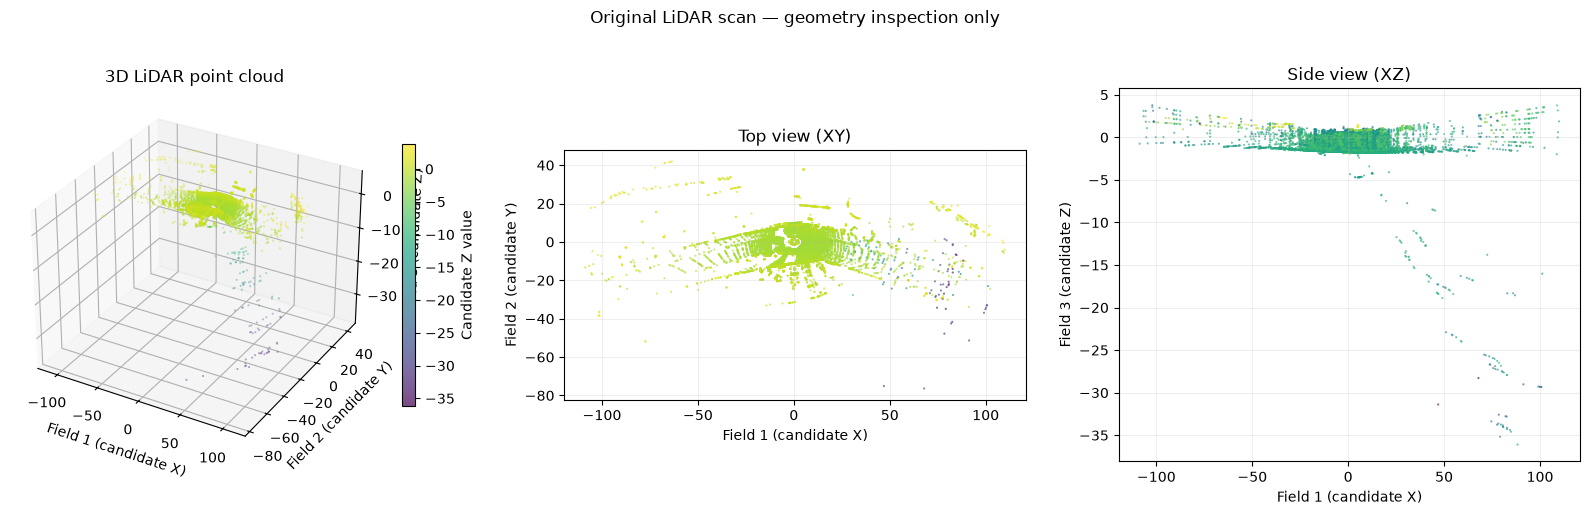

In [3]:
# Select a representative scan from the matched dataset.
# Change SAMPLE_FRAME_ID if a different frame is preferred.
SAMPLE_FRAME_ID = matched_stems[0]
sample_bin_path = lidar_by_stem[SAMPLE_FRAME_ID]

raw_values = np.fromfile(sample_bin_path, dtype=np.float32)
if raw_values.size % 5 != 0:
    raise ValueError(
        f"Unexpected number of float32 values in {sample_bin_path.name}: "
        f"{raw_values.size} is not divisible by 5."
    )

point_records = raw_values.reshape(-1, 5)
candidate_xyz = point_records[:, :3]

# Remove records with non-finite candidate coordinates.
finite_mask = np.isfinite(candidate_xyz).all(axis=1)
xyz = candidate_xyz[finite_mask]

# Deterministic subsampling keeps plotting responsive while preserving the scan shape.
MAX_PLOT_POINTS = 30000
if len(xyz) > MAX_PLOT_POINTS:
    rng = np.random.default_rng(42)
    selected = rng.choice(len(xyz), size=MAX_PLOT_POINTS, replace=False)
    xyz_plot = xyz[selected]
else:
    xyz_plot = xyz

print(f"Frame: {SAMPLE_FRAME_ID}")
print(f"Total records: {len(point_records):,}")
print(f"Records with finite candidate XYZ: {len(xyz):,}")
print(f"Points rendered: {len(xyz_plot):,}")
print("Coordinate interpretation is provisional; units and reference frame are not yet verified.")

fig = plt.figure(figsize=(16, 5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
scatter = ax1.scatter(
    xyz_plot[:, 0], xyz_plot[:, 1], xyz_plot[:, 2],
    c=xyz_plot[:, 2], s=0.25, cmap="viridis", alpha=0.7
)
ax1.set_title("3D LiDAR point cloud")
ax1.set_xlabel("Field 1 (candidate X)")
ax1.set_ylabel("Field 2 (candidate Y)")
ax1.set_zlabel("Field 3 (candidate Z)")

ax2 = fig.add_subplot(1, 3, 2)
ax2.scatter(xyz_plot[:, 0], xyz_plot[:, 1], c=xyz_plot[:, 2],
            s=0.25, cmap="viridis", alpha=0.7)
ax2.set_title("Top view (XY)")
ax2.set_xlabel("Field 1 (candidate X)")
ax2.set_ylabel("Field 2 (candidate Y)")
ax2.set_aspect("equal", adjustable="box")
ax2.grid(alpha=0.2)

ax3 = fig.add_subplot(1, 3, 3)
ax3.scatter(xyz_plot[:, 0], xyz_plot[:, 2], c=xyz_plot[:, 1],
            s=0.25, cmap="viridis", alpha=0.7)
ax3.set_title("Side view (XZ)")
ax3.set_xlabel("Field 1 (candidate X)")
ax3.set_ylabel("Field 3 (candidate Z)")
ax3.set_aspect("auto")
ax3.grid(alpha=0.2)

fig.colorbar(scatter, ax=ax1, shrink=0.7, label="Candidate Z value")
fig.suptitle("Original LiDAR scan — geometry inspection only", y=1.02)
plt.tight_layout()
plt.show()


## 5. Frame-level LiDAR measurements

For each matched frame, the analysis calculates:

1. `lidar_point_count`: `.bin` file size divided by 20 bytes per record, after checking divisibility.
2. `projected_valid_pixels`: number of finite, positive pixels in the `.npz` array.
3. `projected_coverage_pct`: valid projected pixels divided by the total number of pixels, expressed as a percentage.

The median and 90th percentile of positive projected values are retained for potential later investigation. Their physical meaning and units are not assumed.


In [4]:
BYTES_PER_LIDAR_RECORD = 5 * np.dtype(np.float32).itemsize
records = []

for frame_id in matched_stems:
    bin_path = lidar_by_stem[frame_id]
    npz_path = projected_by_stem[frame_id]

    bin_size = bin_path.stat().st_size
    if bin_size % BYTES_PER_LIDAR_RECORD != 0:
        raise ValueError(
            f"Unexpected BIN size for {frame_id}: {bin_size} bytes is not "
            f"divisible by {BYTES_PER_LIDAR_RECORD}."
        )
    point_count = bin_size // BYTES_PER_LIDAR_RECORD

    with np.load(npz_path, allow_pickle=False) as npz:
        if "arr_0" not in npz.files:
            raise KeyError(f"'arr_0' not found in {npz_path}; arrays: {npz.files}")
        projected = npz["arr_0"]

    valid = np.isfinite(projected) & (projected > 0)
    valid_values = projected[valid]
    total_pixels = projected.size

    records.append({
        "frame_id": frame_id,
        "lidar_point_count": int(point_count),
        "lidar_file_size_mb": bin_size / (1024 ** 2),
        "projected_height": int(projected.shape[0]),
        "projected_width": int(projected.shape[1]),
        "projected_total_pixels": int(total_pixels),
        "projected_valid_pixels": int(valid.sum()),
        "projected_coverage_pct": 100.0 * valid.sum() / total_pixels,
        "projected_value_median": float(np.median(valid_values)) if valid_values.size else np.nan,
        "projected_value_p90": float(np.percentile(valid_values, 90)) if valid_values.size else np.nan,
    })

lidar_metrics = pd.DataFrame(records)
print("Frame-level metrics:", lidar_metrics.shape)
display(lidar_metrics.head())

Frame-level metrics: (12997, 10)


,frame_id,lidar_point_count,lidar_file_size_mb,projected_height,projected_width,projected_total_pixels,projected_valid_pixels,projected_coverage_pct,projected_value_median,projected_value_p90
0,2018-02-03_20-48-35_00400,110514,2.107887,1024,1920,1966080,8618,0.438334,15.543564,50.096653
1,2018-02-03_20-48-35_00500,110206,2.102013,1024,1920,1966080,8751,0.445099,14.775754,26.601124
2,2018-02-03_20-49-38_00000,110445,2.106571,1024,1920,1966080,8271,0.420685,13.140821,41.407955
3,2018-02-03_20-49-38_00100,110451,2.106686,1024,1920,1966080,8978,0.456645,11.882380,19.281923
4,2018-02-03_20-49-38_00200,110499,2.107601,1024,1920,1966080,8116,0.412801,12.783498,45.173042


### Dataset-wide descriptive statistics

The overall distribution provides a baseline before frames are grouped by environmental labels. The 25th, 50th, and 75th percentiles represent the lower quartile, median, and upper quartile. The median is less sensitive than the mean to unusually large or small scans.


In [5]:
primary_metrics = ["lidar_point_count", "projected_valid_pixels", "projected_coverage_pct"]
display(lidar_metrics[primary_metrics].describe().T)

,count,mean,std,min,25%,50%,75%,max
lidar_point_count,12997.0,55917.168116,17640.095714,8833.0,46794.000000,54951.000000,55249.000000,123258.000000
projected_valid_pixels,12997.0,4363.238670,1363.298549,0.0,3949.000000,4230.000000,4422.000000,10502.000000
projected_coverage_pct,12997.0,0.221926,0.069341,0.0,0.200857,0.215149,0.224915,0.534159


## 6. Environmental metadata integration

Environmental annotations are sourced from the Stage 1 RGB analysis. The notebook identifies the metadata column containing the frame identifier, extracts the identifier, and performs a one-to-one left join.

The metadata match flag is calculated before merging. This ensures that the reported match rate reflects actual key correspondence rather than the row preservation behaviour of a left join.


In [6]:
environment = pd.read_csv(ENVIRONMENT_CSV)
frame_pattern = re.compile(r"\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2}_\d{5}")

def extract_frame_id(value):
    if pd.isna(value):
        return None
    match = frame_pattern.search(str(value))
    return match.group(0) if match else None

matched_set = set(matched_stems)
candidate_scores = {
    column: int(environment[column].map(extract_frame_id).isin(matched_set).sum())
    for column in environment.columns
}
score_series = pd.Series(candidate_scores).sort_values(ascending=False)
display(score_series.to_frame("matching_frame_ids").head(8))

best_metadata_key = score_series.index[0]
if score_series.iloc[0] == 0:
    raise ValueError("Could not find a metadata column containing the frame IDs.")

environment = environment.copy()
environment["frame_id"] = environment[best_metadata_key].map(extract_frame_id)
environment = environment.dropna(subset=["frame_id"])

duplicate_count = int(environment["frame_id"].duplicated().sum())
if duplicate_count:
    print(f"Warning: {duplicate_count} duplicate metadata IDs; keeping the first occurrence.")
environment = environment.drop_duplicates("frame_id", keep="first")
environment["metadata_matched"] = True

analysis_df = lidar_metrics.merge(
    environment, on="frame_id", how="left", validate="one_to_one"
)
analysis_df["metadata_matched"] = analysis_df["metadata_matched"].fillna(False)
match_rate = analysis_df["metadata_matched"].mean()

print(f"Selected metadata key: {best_metadata_key}")
print(f"Metadata match rate: {match_rate:.1%}")
print(f"Frames without environmental metadata: {(~analysis_df['metadata_matched']).sum():,}")
print("Joined analysis table:", analysis_df.shape)

,matching_frame_ids
image_name,12997
image_path,12997
width,0
height,0
channels,0
dtype,0
brightness_mean,0
contrast_std,0


Selected metadata key: image_name
Metadata match rate: 100.0%
Frames without environmental metadata: 0
Joined analysis table: (12997, 27)


### Result 2 — complete environmental annotation coverage

The selected metadata key is `image_name`. All **12,997 of 12,997** LiDAR frames match an environmental annotation. The environmental comparisons therefore use the complete set of matched LiDAR frames without loss at the metadata-join stage.


## 7. Descriptive comparison across environmental categories

For each category, the analysis reports group size, mean, median, and standard deviation for the primary LiDAR measures. Group size is included to provide context when interpreting differences, particularly for categories represented by relatively few frames.


In [7]:
def find_label_column(columns, keywords):
    matches = [
        column for column in columns
        if any(keyword in column.lower() for keyword in keywords)
    ]
    return matches[0] if matches else None

label_columns = {
    "fog": find_label_column(analysis_df.columns, ["fog"]),
    "precipitation": find_label_column(analysis_df.columns, ["precip"]),
    "day_night": find_label_column(analysis_df.columns, ["day_night", "daynight", "day"]),
    "road": find_label_column(analysis_df.columns, ["road"]),
}
print("Environmental label columns:", label_columns)

summary_tables = {}
for dimension, column in label_columns.items():
    if column is None:
        continue
    summary = (
        analysis_df.dropna(subset=[column])
        .groupby(column)
        .agg(
            frame_count=("frame_id", "count"),
            points_mean=("lidar_point_count", "mean"),
            points_median=("lidar_point_count", "median"),
            points_std=("lidar_point_count", "std"),
            coverage_median=("projected_coverage_pct", "median"),
        )
        .sort_values("frame_count", ascending=False)
    )
    summary_tables[dimension] = summary
    print(f"\n{dimension.upper()} — grouped by {column}")
    display(summary.round(3))

Environmental label columns: {'fog': 'fog_condition', 'precipitation': 'precipitation_condition', 'day_night': 'daytime_condition', 'road': 'road_condition'}

FOG — grouped by fog_condition


,frame_count,points_mean,points_median,points_std,coverage_median
fog_condition,,,,,
none,9743,58413.449,54989.0,18381.416,0.216
light,1968,54139.589,55015.0,10146.132,0.220
dense,1286,39725.110,39013.5,10652.732,0.159



PRECIPITATION — grouped by precipitation_condition


,frame_count,points_mean,points_median,points_std,coverage_median
precipitation_condition,,,,,
none,7978,56336.198,54901.0,20749.150,0.212
light_snow,3607,53885.180,54921.0,8247.087,0.217
heavy_snow,1130,55432.217,55177.0,6653.088,0.225
rain,282,71996.457,55319.0,28295.948,0.221



DAY_NIGHT — grouped by daytime_condition


,frame_count,points_mean,points_median,points_std,coverage_median
daytime_condition,,,,,
day,7748,54734.766,54936.5,17056.344,0.214
night,5249,57662.501,54971.0,18330.852,0.216



ROAD — grouped by road_condition


,frame_count,points_mean,points_median,points_std,coverage_median
road_condition,,,,,
wet,4083,54387.127,54941.0,16759.807,0.208
dry,3390,63166.910,54903.5,26988.447,0.215
full_snow,3335,51833.504,54867.0,5623.513,0.220
partial_snow,2179,53666.471,55081.0,5114.738,0.217
unknown,10,75299.100,55360.0,30522.968,0.339


### Result 3 — dense fog is associated with lower LiDAR availability measures

The group summaries show a distinct reduction in dense fog, while light fog and no fog have nearly identical median point counts. The same broad pattern is present in projected coverage.

| Fog category | Frames | Median LiDAR points | Median projected coverage |
|---|---:|---:|---:|
| None | 9,743 | 54,989 | 21.62% |
| Light | 1,968 | 55,015 | 21.96% |
| Dense | 1,286 | 39,014 | 15.93% |

Relative to no-fog frames, dense-fog frames have approximately **29.0% fewer median LiDAR records** and **26.3% lower median projected coverage**. Light fog does not show a comparable reduction.

Median point counts vary much less across day/night, precipitation, and road-condition categories. The rain group contains only **282 frames**, so estimates for this category should be interpreted cautiously. These descriptive comparisons identify dense fog as the clearest candidate for further analysis; they do not establish a causal weather effect.


## 8. Distribution-level analysis of fog categories

Median-only comparisons do not show the spread or overlap of observations within each category. Boxplots are used to compare the distributions of `lidar_point_count` and `projected_coverage_pct` across no-fog, light-fog, and dense-fog frames.

The box represents the interquartile range (Q1–Q3), containing the middle 50% of observations. The centre line marks the median. Whiskers extend to the most extreme observations within 1.5 times the interquartile range; observations beyond the whiskers are potential outliers.

Kruskal–Wallis tests assess whether at least one fog category differs in rank distribution. Dunn pairwise comparisons with Holm correction identify which category pairs differ while controlling the family-wise error rate. Neither test establishes causation. Temporal dependence between adjacent frames is an additional limitation, so the tests are treated as exploratory.


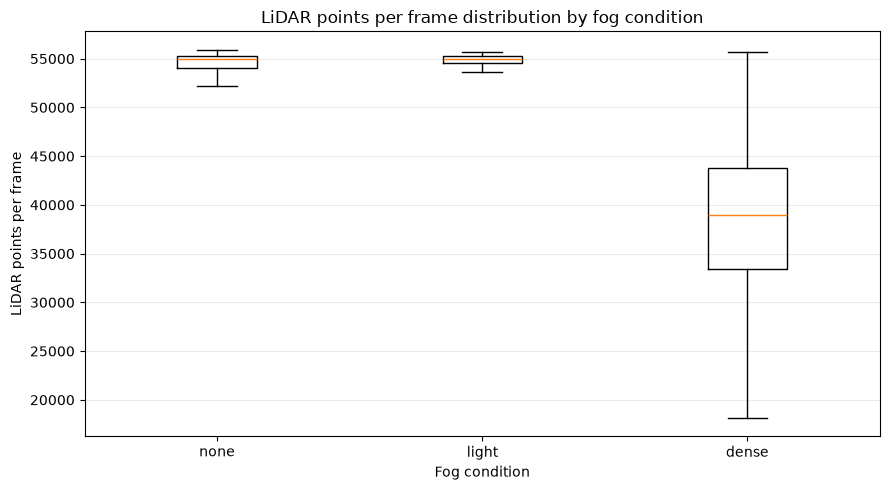

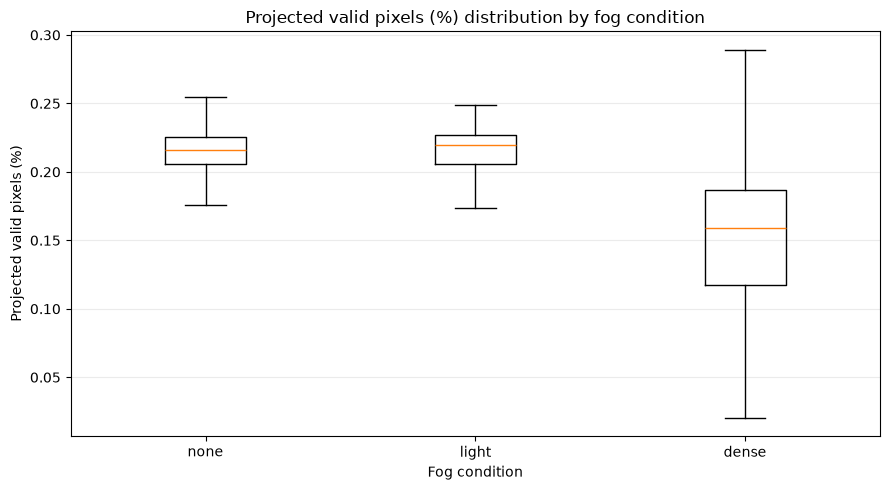

,fog_condition,metric,n,q1_25pct,median_50pct,q3_75pct,iqr_q3_minus_q1
0,none,lidar_point_count,9743,54039.500,54989.000,55270.000,1230.500
1,none,projected_coverage_pct,9743,0.206,0.216,0.225,0.020
2,light,lidar_point_count,1968,54555.500,55015.000,55264.250,708.750
3,light,projected_coverage_pct,1968,0.206,0.220,0.227,0.022
4,dense,lidar_point_count,1286,33440.500,39013.500,43795.250,10354.750
5,dense,projected_coverage_pct,1286,0.117,0.159,0.187,0.070


,metric,kruskal_wallis_H,p_value,epsilon_squared_approx,n_frames,n_groups
0,lidar_point_count,1505.705643,0.0,0.115723,12997,3
1,projected_coverage_pct,1902.942120,0.0,0.146294,12997,3


,metric,group_a,group_b,mean_rank_a,mean_rank_b,z_score,p_uncorrected,p_holm,significant_0_05
0,lidar_point_count,none,light,6917.710561,6944.330539,-0.287078,0.774052,0.774052,False
1,lidar_point_count,none,dense,6917.710561,2645.261664,38.380137,0.000000,0.000000,True
2,lidar_point_count,light,dense,6944.330539,2645.261664,31.954317,0.000000,0.000000,True
3,projected_coverage_pct,none,light,6935.478908,7164.654472,-2.471503,0.013455,0.013455,True
4,projected_coverage_pct,none,dense,6935.478908,2173.477449,42.777884,0.000000,0.000000,True
5,projected_coverage_pct,light,dense,7164.654472,2173.477449,37.098661,0.000000,0.000000,True


In [8]:
from scipy.stats import kruskal, rankdata, norm

FOG_COLUMN = label_columns["fog"]
FOG_ORDER = ["none", "light", "dense"]
FOG_METRICS = {
    "lidar_point_count": "LiDAR points per frame",
    "projected_coverage_pct": "Projected valid pixels (%)",
}

if FOG_COLUMN is None:
    raise ValueError("Could not identify the fog-condition column.")

fog_df = analysis_df[[FOG_COLUMN, *FOG_METRICS.keys()]].copy()
fog_df[FOG_COLUMN] = fog_df[FOG_COLUMN].astype("string").str.strip().str.lower()
fog_categories = [
    category for category in FOG_ORDER
    if category in set(fog_df[FOG_COLUMN].dropna())
]

# Distribution plots and quartile summaries.
for metric, ylabel in FOG_METRICS.items():
    plot_data = [
        fog_df.loc[fog_df[FOG_COLUMN] == category, metric].dropna().to_numpy()
        for category in fog_categories
    ]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.boxplot(plot_data, tick_labels=fog_categories, showfliers=False, whis=1.5)
    ax.set_title(f"{ylabel} distribution by fog condition")
    ax.set_xlabel("Fog condition")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

quartile_rows = []
for category in fog_categories:
    subset = fog_df[fog_df[FOG_COLUMN] == category]
    for metric in FOG_METRICS:
        values = subset[metric].dropna()
        quartile_rows.append({
            "fog_condition": category,
            "metric": metric,
            "n": len(values),
            "q1_25pct": values.quantile(0.25),
            "median_50pct": values.quantile(0.50),
            "q3_75pct": values.quantile(0.75),
            "iqr_q3_minus_q1": values.quantile(0.75) - values.quantile(0.25),
        })
quartile_summary = pd.DataFrame(quartile_rows)
display(quartile_summary.round(3))

# Global Kruskal-Wallis tests.
kw_rows = []
for metric in FOG_METRICS:
    samples = [
        fog_df.loc[fog_df[FOG_COLUMN] == category, metric].dropna().to_numpy()
        for category in fog_categories
    ]
    samples = [sample for sample in samples if len(sample)]
    h_stat, p_value = kruskal(*samples)
    total_n, group_n = sum(map(len, samples)), len(samples)
    eps_sq = (h_stat - group_n + 1) / (total_n - group_n) if total_n > group_n else np.nan
    kw_rows.append({
        "metric": metric,
        "kruskal_wallis_H": h_stat,
        "p_value": p_value,
        "epsilon_squared_approx": eps_sq,
        "n_frames": total_n,
        "n_groups": group_n,
    })
kw_results = pd.DataFrame(kw_rows)
display(kw_results)

# Dunn pairwise comparisons with Holm correction.
# Uses pooled ranks and tie-corrected variance; p-values are two-sided.
def dunn_test_holm(data, group_column, value_column, group_order):
    subset = data[[group_column, value_column]].dropna().copy()
    subset[group_column] = subset[group_column].astype(str)
    subset = subset[subset[group_column].isin(group_order)]

    values = subset[value_column].to_numpy(dtype=float)
    groups = subset[group_column].to_numpy()
    pooled_ranks = rankdata(values, method="average")
    n_total = len(values)

    rank_df = pd.DataFrame({"group": groups, "rank": pooled_ranks})
    rank_stats = rank_df.groupby("group")["rank"].agg(["mean", "count"])

    # Tie correction for the pooled rank variance.
    _, tie_counts = np.unique(values, return_counts=True)
    tie_sum = np.sum(tie_counts**3 - tie_counts)
    tie_correction = 1.0 - tie_sum / (n_total**3 - n_total) if n_total > 1 else 1.0
    rank_variance = (n_total * (n_total + 1) / 12.0) * tie_correction

    pairs = []
    for i, group_a in enumerate(group_order):
        for group_b in group_order[i + 1:]:
            if group_a not in rank_stats.index or group_b not in rank_stats.index:
                continue
            mean_a, n_a = rank_stats.loc[group_a, ["mean", "count"]]
            mean_b, n_b = rank_stats.loc[group_b, ["mean", "count"]]
            standard_error = np.sqrt(rank_variance * (1.0 / n_a + 1.0 / n_b))
            z_score = (mean_a - mean_b) / standard_error
            p_uncorrected = 2.0 * norm.sf(abs(z_score))
            pairs.append({
                "metric": value_column,
                "group_a": group_a,
                "group_b": group_b,
                "mean_rank_a": mean_a,
                "mean_rank_b": mean_b,
                "z_score": z_score,
                "p_uncorrected": p_uncorrected,
            })

    result = pd.DataFrame(pairs)
    if result.empty:
        return result

    # Holm step-down adjustment, preserving original pair order.
    p = result["p_uncorrected"].to_numpy()
    order = np.argsort(p)
    adjusted_sorted = np.maximum.accumulate(
        np.minimum(1.0, (len(p) - np.arange(len(p))) * p[order])
    )
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = adjusted_sorted
    result["p_holm"] = adjusted
    result["significant_0_05"] = result["p_holm"] < 0.05
    return result

dunn_results = pd.concat(
    [
        dunn_test_holm(fog_df, FOG_COLUMN, metric, fog_categories)
        for metric in FOG_METRICS
    ],
    ignore_index=True,
)
display(dunn_results.round(6))


### Statistical interpretation

Interpret the boxplots together with the quartile summary and test results. A lower median accompanied by a shifted interquartile range indicates a broader distributional difference than a median change alone.

The Kruskal–Wallis p-value should be considered alongside the approximate epsilon-squared effect size, the Holm-adjusted Dunn comparisons, and the visual magnitude of the differences. With nearly 13,000 frames, small differences may produce low p-values; statistical significance does not necessarily imply a large practical effect.

Individual outlier markers are suppressed in the boxplots for readability. The quartile table retains the numerical distribution summary.


## 9. Findings and limitations

### Findings supported by the current analysis

- All 12,997 discovered frames have matching filename stems across RGB, original LiDAR, and projected LiDAR files.
- Environmental metadata matches all 12,997 LiDAR frames using `image_name`.
- Dense-fog frames have lower median original point counts and lower median projected coverage than no-fog and light-fog frames.
- No-fog and light-fog frames have nearly identical median point counts.
- Median point counts vary less across precipitation, day/night, and road-condition categories.

### Limitations and unverified assumptions

- The analysis does not establish that fog caused the lower point count or projected coverage.
- Lower stored point count is not necessarily equivalent to lower detection performance or ranging accuracy.
- The official meaning and units of all five `.bin` fields and the projected `.npz` values have not yet been verified.
- Exact temporal synchronization and geometric accuracy of the provided projection have not yet been validated.
- The analysis does not establish that adding LiDAR will improve the RGB YOLO detector.

Potential confounders include scene geometry, object distance, occlusion, sensor configuration, sequence-level sampling, and correlation between adjacent frames. The rain and unknown-road groups are substantially smaller than the main groups. Adjacent frames may be temporally correlated; sequence-aware validation is needed before treating frame-level p-values as definitive.


## 10. Exported analysis tables

The following outputs preserve the frame-matching audit, per-frame LiDAR measurements, and environmental metadata join. They provide reproducible inputs for subsequent sequence-aware analysis.


In [9]:
OUTPUT_DIR = PROJECT_DIR / "outputs" / "stage3_lidar_exploration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

matching_table.to_csv(OUTPUT_DIR / "lidar_rgb_frame_matching.csv", index=False)
lidar_metrics.to_csv(OUTPUT_DIR / "lidar_frame_metrics.csv", index=False)
analysis_df.to_csv(OUTPUT_DIR / "lidar_environment_analysis.csv", index=False)
quartile_summary.to_csv(OUTPUT_DIR / "fog_distribution_quartiles.csv", index=False)
kw_results.to_csv(OUTPUT_DIR / "fog_kruskal_wallis_results.csv", index=False)
dunn_results.to_csv(OUTPUT_DIR / "fog_dunn_holm_results.csv", index=False)

print("Saved analysis outputs to:", OUTPUT_DIR)
for filename in [
    "lidar_rgb_frame_matching.csv",
    "lidar_frame_metrics.csv",
    "lidar_environment_analysis.csv",
    "fog_distribution_quartiles.csv",
    "fog_kruskal_wallis_results.csv",
    "fog_dunn_holm_results.csv",
]:
    print("-", filename)

Saved analysis outputs to: /home/maritza/projects/autonomous_vehicle/outputs/stage3_lidar_exploration
- lidar_rgb_frame_matching.csv
- lidar_frame_metrics.csv
- lidar_environment_analysis.csv
- fog_distribution_quartiles.csv
- fog_kruskal_wallis_results.csv
- fog_dunn_holm_results.csv


## 11. Engineering implications and next steps

The exploratory results identify **dense fog as the highest-priority condition for further LiDAR investigation**. Before attributing the observed reduction to weather, the data-generation and geometry assumptions should be validated and potential sequence-level confounding should be examined.

Recommended follow-up work:

1. Verify the official `.bin` record schema, coordinate frame, and units.
2. Determine whether dense-fog frames are concentrated in particular drives, sequences, or acquisition periods.
3. Compare distributions within matched or comparable sequences rather than treating every frame as independent.
4. In the next stage, inspect RGB images alongside projected LiDAR and validate LiDAR-to-camera geometry before associating LiDAR measurements with YOLO detections.

Only after these checks should the project evaluate whether LiDAR contributes useful information beyond the RGB perception baseline.
